# Cylindrical refolded isocline — LDI ensemble

The LDI fit of `07b_cylindrical_isocline_ldi`, repeated for an ensemble of Fourier bases:
each member draws new wavevectors (one velocity seed) and is otherwise fitted exactly like
the single fit. The settings are read from `results/fit_settings.json` (written by 07b), and
the grid and sections from `results/inputs.npz`. Only LDI: Surfe has no random basis, so its
single fit (07c) is the comparison.

For every member, the measures of 07b: interior extrema, the restored-level misfit, the
younging, the contacts against the truth on the sections (`isocline_inputs.contact_misfit`)
and the intersection over union of each unit between two horizons with the true one
(`isocline_inputs.unit_iou`). The Surfe fit is scored the same way from its saved φ.

Saved to `results/ensemble/`: `ensemble.json` (settings, seeds, per-member measures and the
Surfe numbers) and `ensemble.npz` (each member's φ on the sections).

## Setup

In [1]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import torch

import curlew
from curlew.core import CSet, HSet
from curlew.geometry import Grid
from curlew.geology import restore
from curlew.kinematics.euler import euler_velocity
from curlew.io import loadModel, saveModel

import sys
sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics, exploded3d
import diagnostics
import isocline_inputs  # the processed data from 07a, and the comparison measures
from flat_reference import FlatReference

curlew.device = "cuda" if torch.cuda.is_available() else "cpu"
curlew.dtype = torch.float32
curlew.default_dim = 3

RES_DIR = isocline_inputs.RESULTS_DIR
OUT_DIR = RES_DIR / "ensemble"
OUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR = OUT_DIR / "models"          # every member's fitted model, to evaluate on a finer grid later
MODEL_DIR.mkdir(parents=True, exist_ok=True)
REFIT = False                           # False: a member with a saved model is loaded and evaluated, not refitted

P = json.loads((RES_DIR / "fit_settings.json").read_text())
print(json.dumps(P, indent=1))

{
 "seed": 404,
 "velocity_seed": 42404,
 "lsr": [
  700.0,
  2336.9693375703528
 ],
 "lsr_data_derived": [
  584.2423343925882,
  2336.9693375703528
 ],
 "n_features": 256,
 "n_directions": 32,
 "modes_per_octave": 128,
 "band_info": {
  "m0": 17833.84635050669,
  "m2": 3.1571206859097507,
  "m4": 0.0003651445935485031,
  "lambda_x": 584.2423343925882,
  "lambda_0": null,
  "normal": [
   -0.9407519604783487,
   3.942372556424073e-10,
   -0.33909548633997366
  ],
  "normal_from_contacts": true,
  "resolved": true,
  "lambda_x_error": 0.3447048373466924,
  "n_curvature": 25.688165436354144,
  "window": null,
  "contact_noise": null,
  "n_eff": 1.0000000000000002,
  "n_bedding": 56,
  "n_contacts": 102,
  "n_pairs": 50,
  "n_windows": 0,
  "n_horizons_spanning": 3,
  "profile": true,
  "diameter": 1200.5280447930777,
  "curvature_modes": null,
  "orientations_only": false,
  "strain": null
 },
 "n_steps": 0,
 "epochs": 3000,
 "weights": {
  "grad_loss": "1.",
  "eq_loss": "0.1"
 },
 "iq

## Data, grid and Surfe

As in 07b, on the grid and sections 07b saved. `SURFE_TAG` is the Surfe fit of 07c to
compare with.

In [2]:
SURFE_TAG = "surfe_aniso100000"

data = isocline_inputs.load_processed()
horizons, names = data["horizons"], data["horizon_names"]
gp, gv, hinge = data["gp"], data["gv"], data["hinge"]
C = CSet(gp=gp, gv=gv, eq=[h.astype(np.float32) for h in horizons],
         iq=(P["iq_samples"], [(horizons[i], horizons[i + 1], ">") for i in range(len(horizons) - 1)]))

inp = np.load(RES_DIR / "inputs.npz")
x, y, z, sections, box = inp["x"], inp["y"], inp["z"], inp["sections"], inp["box"]
G = Grid(tuple(float(v) for v in np.ptp(box, axis=0)), step=(P["grid_step"],) * 3,
         center=tuple(box.mean(axis=0).tolist()), sampleArgs=dict(N=128))
assert all(np.allclose(a, b) for a, b in zip(G.tformed_axes, (x, y, z))), "grid differs from 07b's"
grd = torch.tensor(G.coords(), dtype=curlew.dtype, device=curlew.device)
j_sec = [int(np.argmin(np.abs(y - ys))) for ys in sections]


def scores(phi, isovalues):
    misfit = isocline_inputs.contact_misfit(x, y, z, phi, isovalues, data["truth_points"], sections)
    iou = isocline_inputs.unit_iou(x, y, z, phi, isovalues, data["truth_lines"], sections)
    finite = misfit["to_truth"][np.isfinite(misfit["to_truth"])]
    # topology and dip: what the IoU, scored only between true contacts, cannot see
    loops = isocline_inputs.closed_loops(x, y, z, phi, isovalues, sections)
    dip = isocline_inputs.dip_error(x, y, z, phi, data["truth_lines"], sections)
    return dict(closed_loops=int(loops.sum()),
                dip_error_deg_median=float(np.median(dip["angle_deg"])),
                dip_error_deg_p90=float(np.percentile(dip["angle_deg"], 90)),
                contact_to_model_m_median=float(np.median(misfit["to_model"])),
                contact_to_model_m_p90=float(np.percentile(misfit["to_model"], 90)),
                isoline_to_truth_m_median=float(np.median(finite)),
                isoline_to_truth_m_p90=float(np.percentile(finite, 90)),
                contact_distance_m_median=float(np.median(np.r_[misfit["to_model"], finite])),
                unit_iou=np.median(iou, axis=0).tolist())


S = np.load(RES_DIR / f"{SURFE_TAG}.npz")
# One definition of an extremum for every model: a zero of the in-plane gradient on the figure section (each is a line
# along the hinge). SURFE's come from 07c; each member's are found on the same section below.
sec_x, sec_y = np.asarray(S["section_x"], dtype=float), float(S["section_y"])
surfe = {"extrema": int(sum(k in ("maximum", "minimum") for k in S["section_critical_kinds"])),
         **scores(S["phi"], S["isovalues"])}
print(f"{SURFE_TAG}: {surfe['extrema']} extrema, {surfe['closed_loops']} closed isocontours, "
      f"contact distance {surfe['contact_distance_m_median']:.1f} m, IoU {np.round(surfe['unit_iou'], 2)}, "
      f"dip error {surfe['dip_error_deg_median']:.1f}° (P90 {surfe['dip_error_deg_p90']:.1f}°)")

surfe_aniso100000: 14 extrema, 16 closed isocontours, contact distance 4.4 m, IoU [0.69 0.64], dip error 7.1° (P90 30.3°)


## Fit

The construction of 07b for any velocity seed.

In [3]:
n_ref = np.asarray(P["reference_normal"], dtype=float)
reference = FlatReference(n_ref)

def fit_ldi(seed):
    torch.manual_seed(int(seed))
    velocity = euler_velocity(
        3, n_features=P["n_features"], n_directions=P["n_directions"], length_scale_range=tuple(P["lsr"]),
        stream="alpha", activation="cubic", seed=int(seed), hinge=hinge, cylindrical=True,
        energy_normalised=True,
    )
    event = restore(
        f"isocline_{seed}", C=C, H=HSet().zero(**P["weights"]), velocity=velocity,
        n_steps=P["n_steps"], integrator=P.get("integrator", "shear"), depth_axis=reference.depth_axis, reference=reference,
        init_std=P.get("init_std", 0.0), sigma_floor=0.0, signed_normals=True, learning_rate=P["lr_adam"],
        pin=torch.zeros(3, dtype=curlew.dtype, device=curlew.device),
        optimizer={"amplitude": (torch.optim.SGD, dict(lr=P["lr_sgd"], momentum=P["amp_momentum"], nesterov=True)),
                   "shape": (torch.optim.Adam, dict(lr=P["lr_adam"]))},
    )
    for name, h in zip(names, horizons):
        event.addIsosurface(name, seed=h)
    model = curlew.GeoModel([event])
    model.prefit(epochs=P["epochs"], vb=True, early_stop=None, best=True)
    return model, event


def section_critical(event):
    """The field's critical points on the figure section: zeros of its exact in-plane gradient (as 07d does for the single fit)."""
    def grad(p):
        q = torch.as_tensor(np.c_[p[:, 0], np.full(len(p), sec_y), p[:, 1]], dtype=curlew.dtype, device=curlew.device)
        g, _ = event.field.gradient(q, normalize=False, return_value=True)
        return g.detach().cpu().numpy()[:, [0, 2]]
    return diagnostics.find_critical_points(None, sec_x, z, gradient=grad)


def member(seed):
    t0 = time.perf_counter()
    path = MODEL_DIR / f"member_{int(seed)}.pt"
    if path.exists() and not REFIT:        # a saved member: evaluate it, no refit
        model = loadModel(path)
        event = model.events[0]
    else:
        model, event = fit_ldi(seed)
        saveModel(path, model)
    field = event.field
    with torch.no_grad():
        restored = [field.inverse_map(torch.as_tensor(h, dtype=curlew.dtype, device=curlew.device)).cpu().numpy()
                    for h in horizons]
        n_pred = field.predict_normals(torch.as_tensor(gp, dtype=curlew.dtype, device=curlew.device)).cpu().numpy()
        phi = G.reshape(np.asarray(model.predict(grd, litho=False).scalar, dtype=float))
    iso = {str(k): float(v) for k, v in event.getIsovalues().items()}
    isovalues = np.array([iso[n] for n in names])
    pred = n_pred / np.linalg.norm(n_pred, axis=1, keepdims=True).clip(min=1e-12)
    cos = np.clip((gv * pred).sum(1), -1.0, 1.0)
    crit = section_critical(event)
    return dict(seed=int(seed), extrema=int(crit.extrema_count), saddles=int(crit.counts["saddle"]),
                restored_level_sd_m=[float((r @ n_ref).std()) for r in restored],
                younging_deg_median=float(np.median(np.degrees(np.arccos(cos)))),
                fraction_reversed=float(np.mean(cos < 0)),
                **scores(phi, isovalues), isovalues=isovalues.tolist(),
                phi_sections=phi[:, j_sec, :].astype(np.float32), seconds=time.perf_counter() - t0)

## Ensemble

`N_ENSEMBLE` velocity seeds, drawn once from `ENSEMBLE_RNG_SEED`. 07b's own seed is not
among them, so the single fit is not counted twice.

In [4]:
N_ENSEMBLE = 15
ENSEMBLE_RNG_SEED = 707
seeds = np.random.default_rng(ENSEMBLE_RNG_SEED).integers(0, 2**31 - 1, size=N_ENSEMBLE)

members = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for k, seed in enumerate(seeds):
        r = member(seed)
        members.append(r)
        print(f"{k + 1:2d}/{N_ENSEMBLE} seed {seed}: extrema {r['extrema']}, "
              f"restored sd {np.round(r['restored_level_sd_m'], 1)} m, "
              f"contact distance {r['contact_distance_m_median']:.1f} m, IoU {np.round(r['unit_iou'], 2)}, "
              f"{r['seconds']:.0f} s")

 1/15 seed 676410599: extrema 0, restored sd [13.7  9.9 14.8] m, contact distance 5.3 m, IoU [0.64 0.68], 7 s
 2/15 seed 1359440359: extrema 0, restored sd [15.2 10.5 17.1] m, contact distance 5.2 m, IoU [0.67 0.71], 6 s
 3/15 seed 1652066302: extrema 0, restored sd [13.6  9.4 14.4] m, contact distance 4.9 m, IoU [0.66 0.71], 7 s
 4/15 seed 1269039567: extrema 0, restored sd [14.2 10.3 15.5] m, contact distance 5.0 m, IoU [0.65 0.7 ], 8 s
 5/15 seed 1574609252: extrema 0, restored sd [14.2 10.7 15.1] m, contact distance 4.9 m, IoU [0.66 0.72], 8 s
 6/15 seed 1037267326: extrema 0, restored sd [13.4  9.5 14.3] m, contact distance 4.8 m, IoU [0.65 0.71], 8 s
 7/15 seed 99899120: extrema 0, restored sd [14.4 10.3 19. ] m, contact distance 5.1 m, IoU [0.67 0.69], 6 s
 8/15 seed 77457883: extrema 0, restored sd [13.8  8.  13.6] m, contact distance 4.5 m, IoU [0.68 0.73], 5 s
 9/15 seed 1615239848: extrema 0, restored sd [14.7 10.3 15.3] m, contact distance 5.4 m, IoU [0.66 0.69], 6 s
10/15 

section y = -370 m | 15 members | 119 x 159 cells at 5 m | mean entropy 0.127 bits, 18% of cells uncertain, maximum 1.37 bits


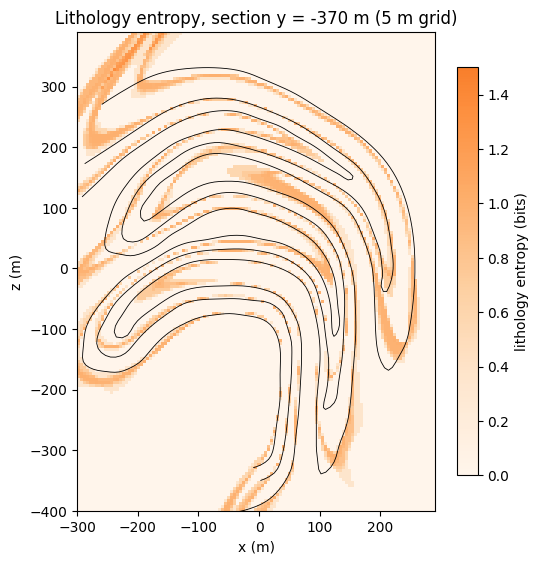

In [5]:
import matplotlib.pyplot as plt
import figstyle
from curlew.io import loadModel
import flat_reference   # the saved models rebuild their reference from this module

SECTION = 0        # which section's y to use (the model is cylindrical, so any y inside the box gives the same picture)
STEP = 5.0         # m, the fine grid (the ensemble's own grid is 10 m)
CHUNK = 50_000     # points per predict call

y0 = float(y[j_sec[SECTION]])
xf = np.arange(x[0], x[-1] + 1e-9, STEP)
zf = np.arange(z[0], z[-1] + 1e-9, STEP)
XX, ZZ = np.meshgrid(xf, zf, indexing="ij")
pts = np.c_[XX.ravel(), np.full(XX.size, y0), ZZ.ravel()]


def litho_section(path):
    """Lithology of one saved member on the fine section (x by z), from model.predict(litho=True)."""
    saved = loadModel(path)
    out = np.empty(len(pts), dtype=np.int16)
    with torch.no_grad():
        for i in range(0, len(pts), CHUNK):
            chunk = torch.as_tensor(pts[i:i + CHUNK], dtype=curlew.dtype, device=curlew.device)
            out[i:i + CHUNK] = np.asarray(saved.predict(chunk, litho=True).lithoID).ravel()
    return out.reshape(XX.shape)


files = sorted(MODEL_DIR.glob("member_*.pt"))
unit_fine = np.stack([litho_section(f) for f in files])                           # member, x, z
classes = np.unique(unit_fine)
share = np.stack([(unit_fine == c).mean(axis=0) for c in classes])                # class, x, z: share of members
entropy_fine = -(share * np.log2(np.clip(share, 1e-12, 1.0))).sum(axis=0)         # bits

print(f"section y = {y0:.0f} m | {len(files)} members | {XX.shape[0]} x {XX.shape[1]} cells at {STEP:g} m | "
      f"mean entropy {entropy_fine.mean():.3f} bits, {(entropy_fine > 0).mean():.0%} of cells uncertain, "
      f"maximum {entropy_fine.max():.2f} bits")

fig_hr, ax_hr = plt.subplots(figsize=(5.5, 6))
vmax = max(0.5, 0.5 * np.ceil(2.0 * entropy_fine.max()))
im_hr = ax_hr.imshow(entropy_fine.T, origin="lower", extent=(xf[0], xf[-1], zf[0], zf[-1]), cmap=figstyle.entropy_cmap(),
                     vmin=0.0, vmax=vmax, interpolation="nearest", aspect="equal")
for h in data["truth_lines"]:                                                      # the true contacts (profile = x, z)
    ax_hr.plot(*np.asarray(h[0]).T, color="k", lw=0.6)
figstyle.set_view(ax_hr, (xf[0], xf[-1]), (zf[0], zf[-1]))                         # stop at the image; lines are clipped there
ax_hr.set(xlabel="x (m)", ylabel="z (m)", title=f"Lithology entropy, section y = {y0:.0f} m ({STEP:g} m grid)")
fig_hr.colorbar(im_hr, ax=ax_hr, shrink=0.8, label="lithology entropy (bits)")
plt.tight_layout()
plt.show()

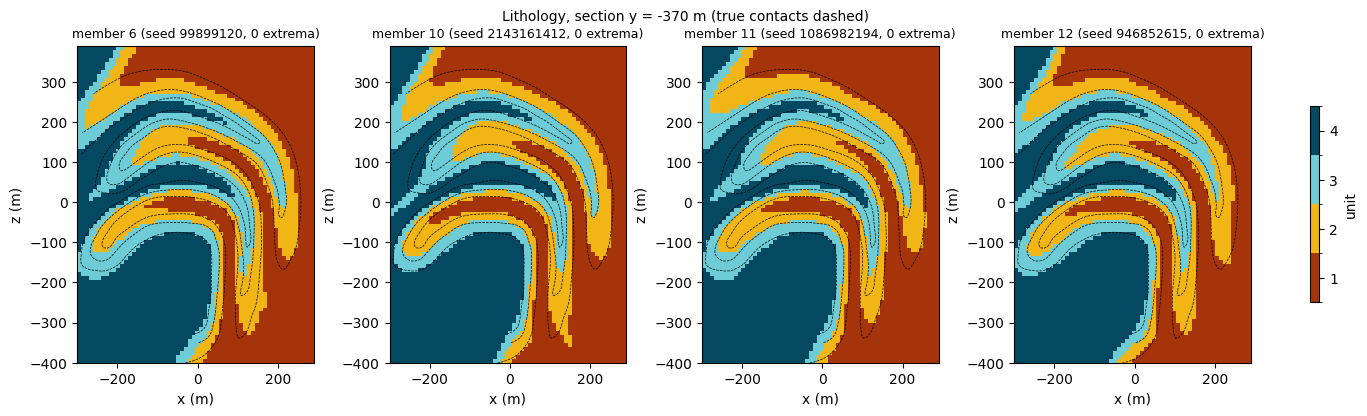

In [6]:
import matplotlib.pyplot as plt
import figstyle

SECTION = 0                 # which saved cross section to draw (they are all cylindrical)
MEMBERS = [6, 10, 11, 12]      # which ensemble members to draw: any indices from 0 to N_ENSEMBLE - 1, in any number
N_COLS = 4


def lithology(k, section=SECTION):
    """Unit of every cell of member k on a section, numbered 1 ... n_horizons + 1 in the order of its isovalues."""
    return isocline_inputs.units(members[k]["phi_sections"][:, section, :], members[k]["isovalues"]) + 1


ids = np.arange(1, len(names) + 2)
cmap_lit, norm_lit = figstyle.litho_cmap(ids)
n_col = min(N_COLS, len(MEMBERS))
n_row = -(-len(MEMBERS) // n_col)
fig_lit, axs_lit = plt.subplots(n_row, n_col, figsize=(3.4 * n_col, 4.0 * n_row), squeeze=False, constrained_layout=True)
for ax_lit, k in zip(axs_lit.ravel(), MEMBERS):
    im_lit = ax_lit.imshow(lithology(k).T, origin="lower", extent=(x[0], x[-1], z[0], z[-1]), cmap=cmap_lit,
                           norm=norm_lit, interpolation="nearest", aspect="equal")
    for h in data["truth_lines"]:                                                  # the true contacts (profile = x, z)
        ax_lit.plot(*np.asarray(h[0]).T, color="k", lw=0.5, ls="--")
    figstyle.set_view(ax_lit, (x[0], x[-1]), (z[0], z[-1]))                        # stop at the image
    ax_lit.set_title(f"member {k} (seed {seeds[k]}, {members[k]['extrema']} extrema)", fontsize=9)
    ax_lit.set(xlabel="x (m)", ylabel="z (m)")
for ax_lit in axs_lit.ravel()[len(MEMBERS):]:                                      # hide unused panels
    ax_lit.set_visible(False)
fig_lit.colorbar(im_lit, ax=axs_lit, shrink=0.6, ticks=ids, label="unit")
fig_lit.suptitle(f"Lithology, section y = {y[j_sec[SECTION]]:.0f} m (true contacts dashed)", fontsize=10)
plt.show()

## Summary

In [7]:
keys = ("seed", "extrema", "saddles", "restored_level_sd_m", "younging_deg_median", "fraction_reversed",
        "contact_to_model_m_median", "contact_to_model_m_p90", "isoline_to_truth_m_median",
        "isoline_to_truth_m_p90", "contact_distance_m_median", "unit_iou", "closed_loops", "dip_error_deg_median",
        "dip_error_deg_p90", "isovalues", "seconds")
summary = {k: [r[k] for r in members] for k in keys}
iou = np.asarray(summary["unit_iou"])
dist = np.asarray(summary["contact_distance_m_median"])
print(f"extrema in {sum(e > 0 for e in summary['extrema'])}/{N_ENSEMBLE} members")
print(f"contact distance: median {np.median(dist):.1f} m (range {dist.min():.1f}-{dist.max():.1f}); "
      f"Surfe {surfe['contact_distance_m_median']:.1f} m")
print(f"IoU (H0–H1, H1–H2): median {np.round(np.median(iou, 0), 2)}, range "
      f"{np.round(iou.min(0), 2)}-{np.round(iou.max(0), 2)}; Surfe {np.round(surfe['unit_iou'], 2)}")
print(f"members above Surfe's IoU, per unit: {(iou > np.asarray(surfe['unit_iou'])).sum(0).tolist()} of {N_ENSEMBLE}")
loops_m, dip_m, dip90_m = (np.asarray(summary[k]) for k in ("closed_loops", "dip_error_deg_median", "dip_error_deg_p90"))
print(f"closed isocontours on the sections: members {loops_m.sum()} in total ({(loops_m > 0).sum()}/{N_ENSEMBLE} members with any); "
      f"Surfe {surfe['closed_loops']}")
print(f"dip error along the true contacts: median {np.median(dip_m):.1f}° (range {dip_m.min():.1f}-{dip_m.max():.1f}), "
      f"P90 {np.median(dip90_m):.1f}°; Surfe {surfe['dip_error_deg_median']:.1f}° (P90 {surfe['dip_error_deg_p90']:.1f}°)")

extrema in 0/15 members
contact distance: median 4.9 m (range 4.5-5.4); Surfe 4.4 m
IoU (H0–H1, H1–H2): median [0.66 0.71], range [0.64 0.68]-[0.68 0.73]; Surfe [0.69 0.64]
members above Surfe's IoU, per unit: [0, 15] of 15
closed isocontours on the sections: members 0 in total (0/15 members with any); Surfe 16
dip error along the true contacts: median 4.1° (range 3.6-4.6), P90 17.8°; Surfe 7.1° (P90 30.3°)


## Save

In [8]:
np.savez_compressed(
    OUT_DIR / "ensemble.npz", seeds=seeds, x=x, z=z, sections=sections, section_y=y[j_sec],
    phi_sections=np.stack([r["phi_sections"] for r in members]),        # member, x, section, z
    isovalues=np.asarray(summary["isovalues"]),
)
(OUT_DIR / "ensemble.json").write_text(json.dumps(
    {"parameters": P, "n_ensemble": N_ENSEMBLE, "rng_seed": ENSEMBLE_RNG_SEED, "members": summary,
     "surfe": {"tag": SURFE_TAG, **surfe}},
    indent=2, default=int))
for f in sorted(OUT_DIR.iterdir()):
    print(f"wrote {f}  ({f.stat().st_size / 1e6:.2f} MB)")

wrote results/ensemble/ensemble.json  (0.01 MB)
wrote results/ensemble/ensemble.npz  (0.28 MB)
wrote results/ensemble/models  (0.00 MB)
